# PS04-AI — Bài làm sinh viên
**Nguyễn Bích Vân -IAI-UET-VNU**

Họ tên: Nguyễn Ngọc Tuấn Minh 

Mã sinh viên: 25022946

Lớp: AI5

Đề trong `PS04_AI_Exercises.pdf`. Bài 1–6 làm tay. Notebook này có mã sẵn cho hai bài kiểm chứng: chỉ cần bật cờ chạy hoặc thay tên tệp/cột. Chưa có đầu ra hay lời nhận xét điền sẵn.

## Khởi động
Mở đúng thư mục có `data/`, chọn kernel rồi chạy ô dưới. Thiếu thư viện: `%pip install -r requirements.txt` trong một ô Code mới, sau đó khởi động lại kernel.

In [10]:
import sys
from pathlib import Path
print("Python của kernel:", sys.executable)
# Nếu thiếu thư viện: chạy %pip install -r requirements.txt trong một ô riêng,
# rồi Restart Kernel. Không dán dấu PS ...> hoặc >> vào notebook.
import numpy as np
import pandas as pd
import plotnine
import statsmodels
from IPython.display import display
from plotnine import (ggplot, aes, geom_point, geom_line, geom_abline,
                      geom_hline, labs, facet_wrap)
ROOT_OVERRIDE = ""  # Ví dụ r"D:\PS04_AI_Student"; để trống khi mở đúng thư mục.
ROOT = Path(ROOT_OVERRIDE).expanduser() if ROOT_OVERRIDE else Path.cwd()
ROOT = ROOT.resolve()
if not (ROOT / "regression_tools.py").is_file():
    raise FileNotFoundError("Mở thư mục có data/ và regression_tools.py, hoặc sửa ROOT_OVERRIDE.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from regression_tools import prepare_data, analyze, numeric_summary, make_plots, save_plots
print("Thư mục bài:", ROOT)
print("NumPy",np.__version__,"pandas",pd.__version__,"plotnine",plotnine.__version__,"statsmodels",statsmodels.__version__)


Python của kernel: c:\Users\admin\AppData\Local\Programs\Python\Python313\python.exe
Thư mục bài: C:\Users\admin\OneDrive\Documents\UET_2026_2027\MATH1052\MATH1052\PS04\PS04_AI_Student
NumPy 2.3.5 pandas 2.2.3 plotnine 0.15.3 statsmodels 0.15.0


## Bài 1–6 — Phần tính tay
Đính kèm bài viết/PDF riêng; không dùng output notebook thay phép tính.

Câu khó nhất với tôi và điều cần hỏi giảng viên: …

## LAB01 — Câu 5 của Bài 7
Trước khi bật mã, trả lời câu 1–4 bằng lời. Sau đó chạy mô hình đơn và mô hình có nhóm trên cùng 54 lượt. Kiểm tra đơn vị một token, không nhầm với trăm token.

exercise07_hardware_groups.csv: ban đầu 54 hàng; giữ 54; loại 0.
Các hàng bị loại là thiếu/không hợp lệ ở đúng các cột đang dùng; không đổi thành 0.


,model,n,SSE,sum_residuals,sum_x_residuals
0,simple,54,76.09912,1.749711e-13,1.312603e-10
1,adjusted,54,21.75405,-3.899592e-11,-2.549606e-08


,coefficient
Intercept,8.006960
x,-0.003088


,coefficient
Intercept,5.700
"C(group, Treatment(reference='Edge'))[T.Cloud]",-7.200
"C(group, Treatment(reference='Edge'))[T.Workstation]",-3.600
x,0.006


Cloud n = 18 r = 0.7499999999453701
Edge n = 18 r = 0.7999999999981035
Workstation n = 18 r = 0.6000000001230325


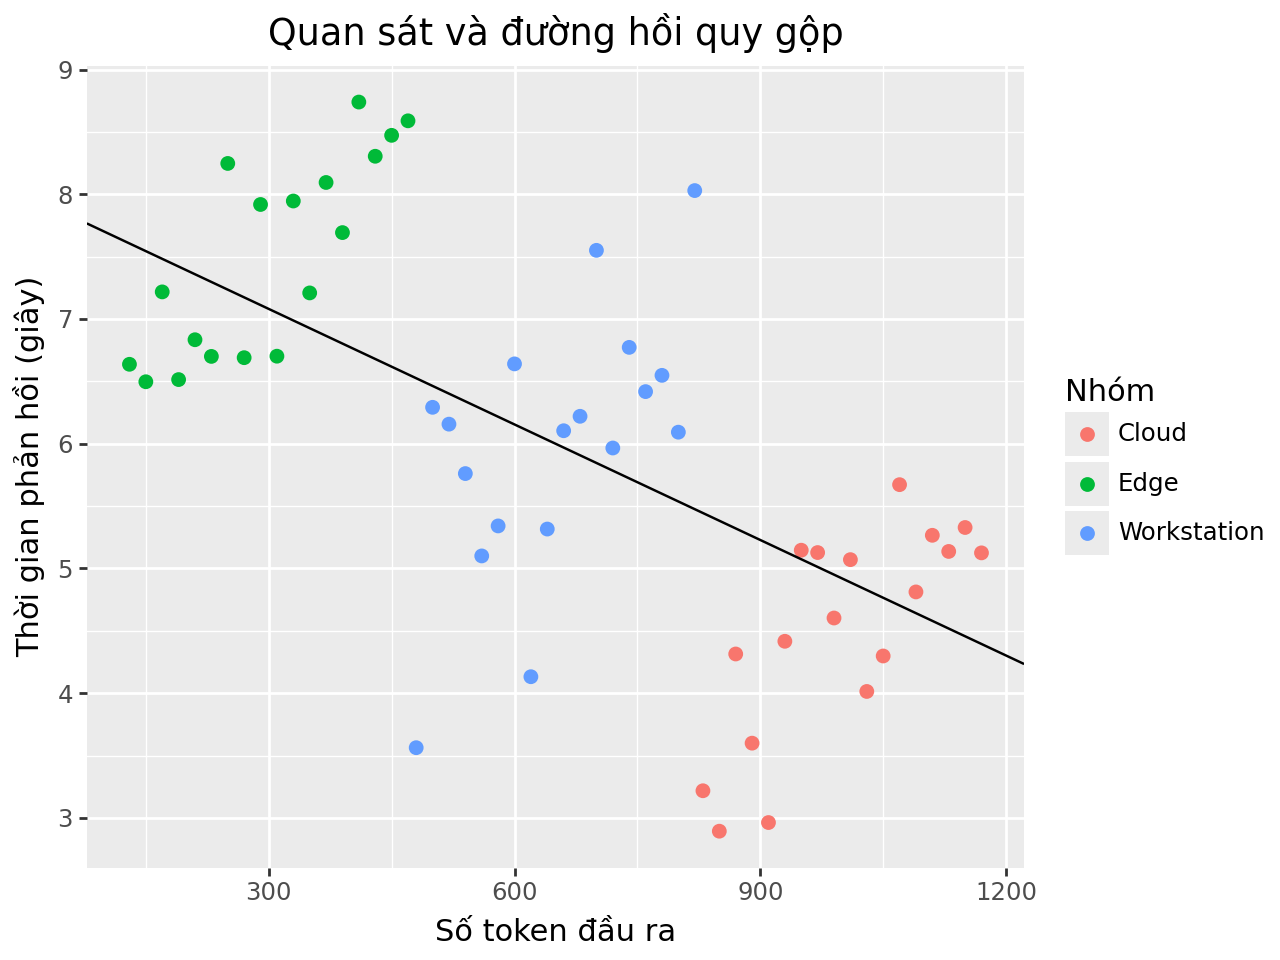

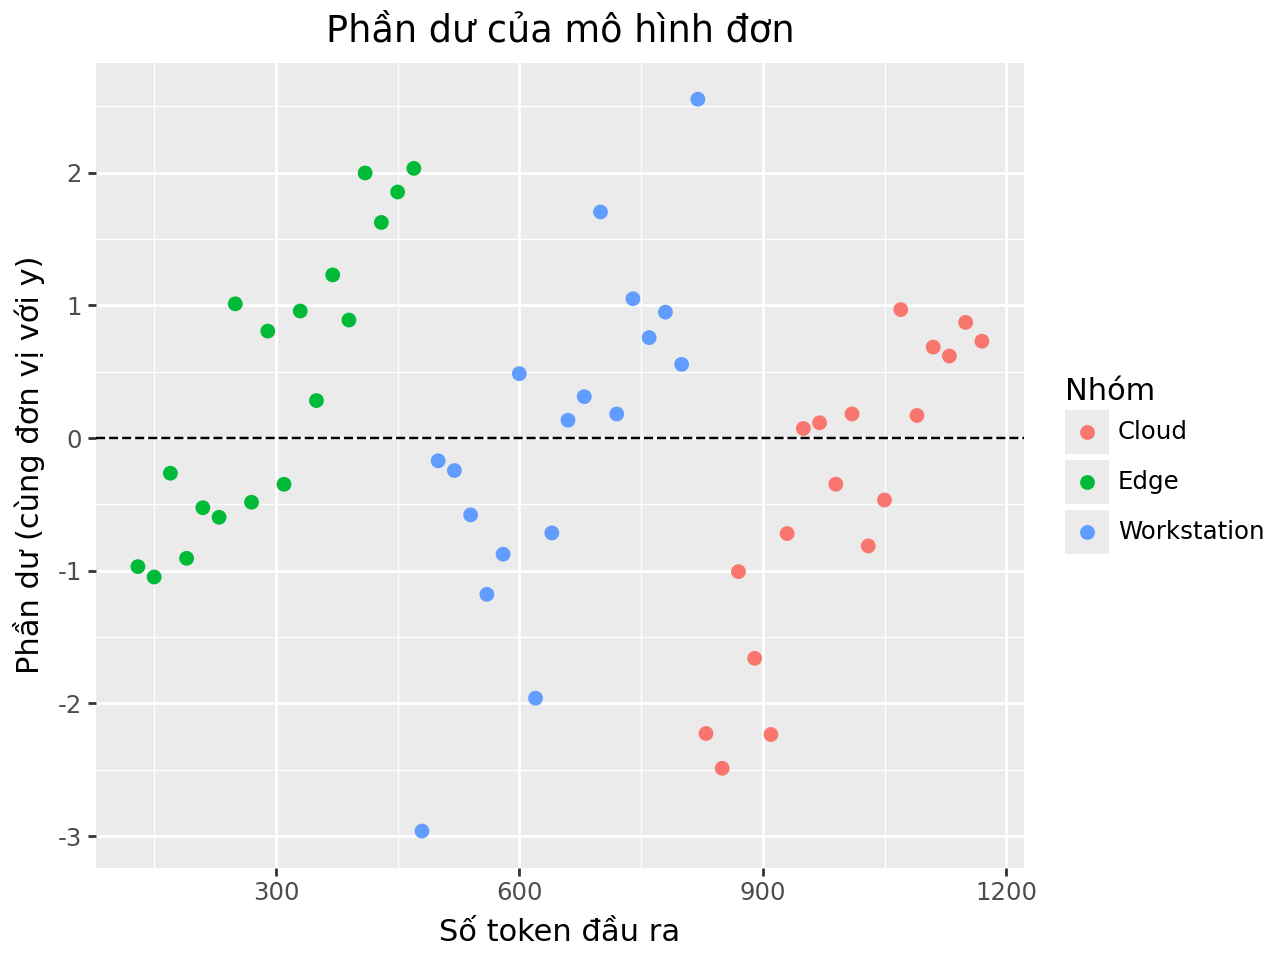

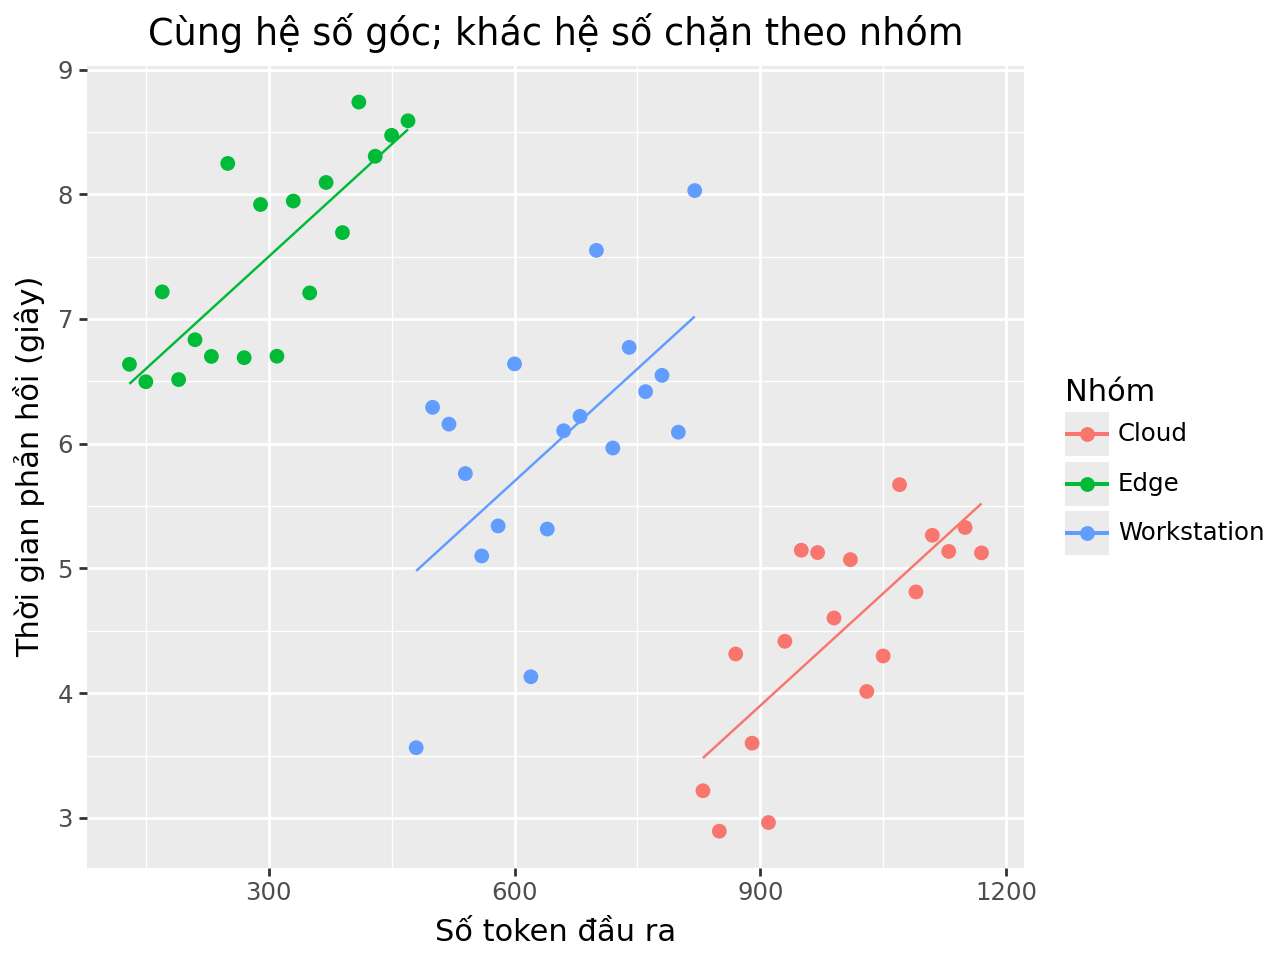

C:\Users\admin\OneDrive\Documents\UET_2026_2027\MATH1052\MATH1052\PS04\PS04_AI_Student\student_outputs\lab01_scatter_and_fit.png
C:\Users\admin\OneDrive\Documents\UET_2026_2027\MATH1052\MATH1052\PS04\PS04_AI_Student\student_outputs\lab01_residuals.png
C:\Users\admin\OneDrive\Documents\UET_2026_2027\MATH1052\MATH1052\PS04\PS04_AI_Student\student_outputs\lab01_adjusted_fit.png


In [11]:
RUN_LAB01 =  True  # Doi thanh True sau khi da tra loi cau 1--4 cua Bai 7.
if RUN_LAB01:
    lab1 = prepare_data(ROOT,"exercise07_hardware_groups.csv",
                        "output_tokens","response_time_s","environment")
    result1 = analyze(lab1,reference="Edge")
    display(numeric_summary(result1))
    display(result1["simple"].params.to_frame("coefficient"))
    display(result1["adjusted"].params.to_frame("coefficient"))
    for group,d in lab1.groupby("group"):
        print(group,"n =",len(d),"r =",d.x.corr(d.y))
    figures1 = make_plots(result1,"Số token đầu ra","Thời gian phản hồi (giây)")
    for p in figures1.values():display(p)
    for path in save_plots(figures1,ROOT/"student_outputs","lab01"):print(path)
else:
    print("LAB01 chưa chạy. Sửa RUN_LAB01=True khi bắt đầu thực hành.")


### Bài 7 — Trả lời bằng lời
1. Bốn hệ số có thể đồng thời đúng không? Bốn hệ số có thể đồng thời đúng vì mỗi hệ số tương quan ứng với một môi trường triển khai. 3 cụm điểm nếu nhìn riêng có thể thấy mối quan hệ tuyến đồng biến (x tăng thì y tăng), nhưng khi nhìn vào toàn bộ quan sát lại nhìn thấy nghịch biến (x tăng y giảm).

2. Chọn hệ số cho câu hỏi trong cùng môi trường: Nên dùng hệ số theo nhóm khi xét trong cùng môi trường.
3. Hai lỗi của câu kết luận: 

     + Chưa xét hệ số tương quan của từng nhóm, hệ số tương quan của từng nhóm có thể khác hoàn toàn so với toàn bộ quan sát(như bài đang xét)
     + Nếu hệ số tương quan âm nhưng gần 0 (|r| ~ 0 ) thì mối liên hệ 2 biến yếu, kết luận như bạn là sai.
4. Biến cần thêm và vì sao: Thêm biến chỉ báo (mỗi môi trường ứng với một biến). Việc thêm giúp nhìn được sự thay đổi của đầu ra y theo x của từng nhóm môi trường thay vì nhìn toàn bộ quan sát.
5. Hệ số trước/sau điều chỉnh, ý nghĩa và giới hạn: 

     + Trước điều chỉnh :  ~ -0.003 < 0
     + Sau điều chỉnh : ~ 0.006 > 0

     * Ý nghĩa : Từ tập dữ liệu được quan sát, số token đầu ra tăng thì thời gian phản hồi có xu hướng tăng khi xét trên cùng môi trường. Khi xét trên toàn bộ quan sát, mối liên hệ ngược lại.
     * Giới hạn : Kết luận đưa ra dựa trên dữ liệu quan sát, không phải thực tế , với các quan sát không trong tập dữ liệu và có số token `x` ở ngoài khoảng quan sát (vd như `x` = 0) thì là ngoại suy.

## Bài 8 — Cấp nhóm không phải cấp yêu cầu
+ A: Khẳng định nhân quả vượt dữ liệu : đưa ra kết luận tổng quát từ dữ liệu hữu hạn quan sát được.

+ B: Không suy ra từ cấp dữ liệu hiện có : Không có giá trị xác suất thiếu căn cứ ở x = 0 ( nằm ngoài 30-85%)

+ C: Khẳng định nhân quả vượt dữ liệu : Dùng mô hình khớp từ dữ liệu quan sát (y = 42 - 0.35x) được để đưa ra kết luận tổng quát.

+ D: Được hỗ trợ ở mức mô tả : Đưa ra từ dữ liệu,nói rằng 2 biến có liên hệ nhưng không khẳng định nhân quả nhân quả

Hai vấn đề cần phân biệt: 

    + Vấn đề của B : So sánh một yêu cầu không nằm trong quan sát với một yêu cầu nằm trong quan sát - và đưa ra kết luận vượt dữ liệu hiện có.
    
    + Vấn đề của C : Kết luận của C chỉ đúng khi x trước vào sau khi tăng 20 điểm phần trăm vẫn nằm trong khoảng 30-85%. Nếu x sau khi tăng 20 điểm vượt ngoài miền quan sát , C vừa mắc cả 2 lỗi kđịnh nhân quả + suy ra vượt cấp dữ liệu.

Biến gây nhiễu : tồn tại một biễn thứ 3 gây nhiễu có thể là "loại dự án", các loại dự án phổ biến, có lời giải sẵn. Khi trích xuất càng nhiều tài liệu thì phần trăm câu trả lời thiếu căn cứ vẫn thấp do số lượng,độ uy tín, phổ biến cao của các loại tài liệu liên quan đến loại dự án đó.

## LAB02 — Câu 5 của Bài 9
Khớp mỗi chiều độc lập. Đừng lấy nghịch đảo slope làm lệnh thay cho khớp `x ~ y`.

In [12]:
RUN_LAB02 = True  # Doi thanh True sau khi da du doan ket qua cua Bai 9.
if RUN_LAB02:
    data = prepare_data(ROOT,"exercise09_forward_reverse.csv",
                        "output_hundreds","response_time_s")
    result = analyze(data)
    CONFIG = {"x_label":"Độ dài đầu ra (trăm token)",
              "y_label":"Thời gian phản hồi (giây)"}
else:
    print("LAB02 chưa chạy. Sửa RUN_LAB02=True khi bắt đầu thực hành.")


exercise09_forward_reverse.csv: ban đầu 9 hàng; giữ 9; loại 0.
Các hàng bị loại là thiếu/không hợp lệ ở đúng các cột đang dùng; không đổi thành 0.


Slope y theo x: 0.800000000333333
Slope x theo y: 0.4500000001725843
Tích slope: 0.3600000002880673 ; r^2 = 0.3600000002880674
Tâm dữ liệu: 6.0 12.799999999777777


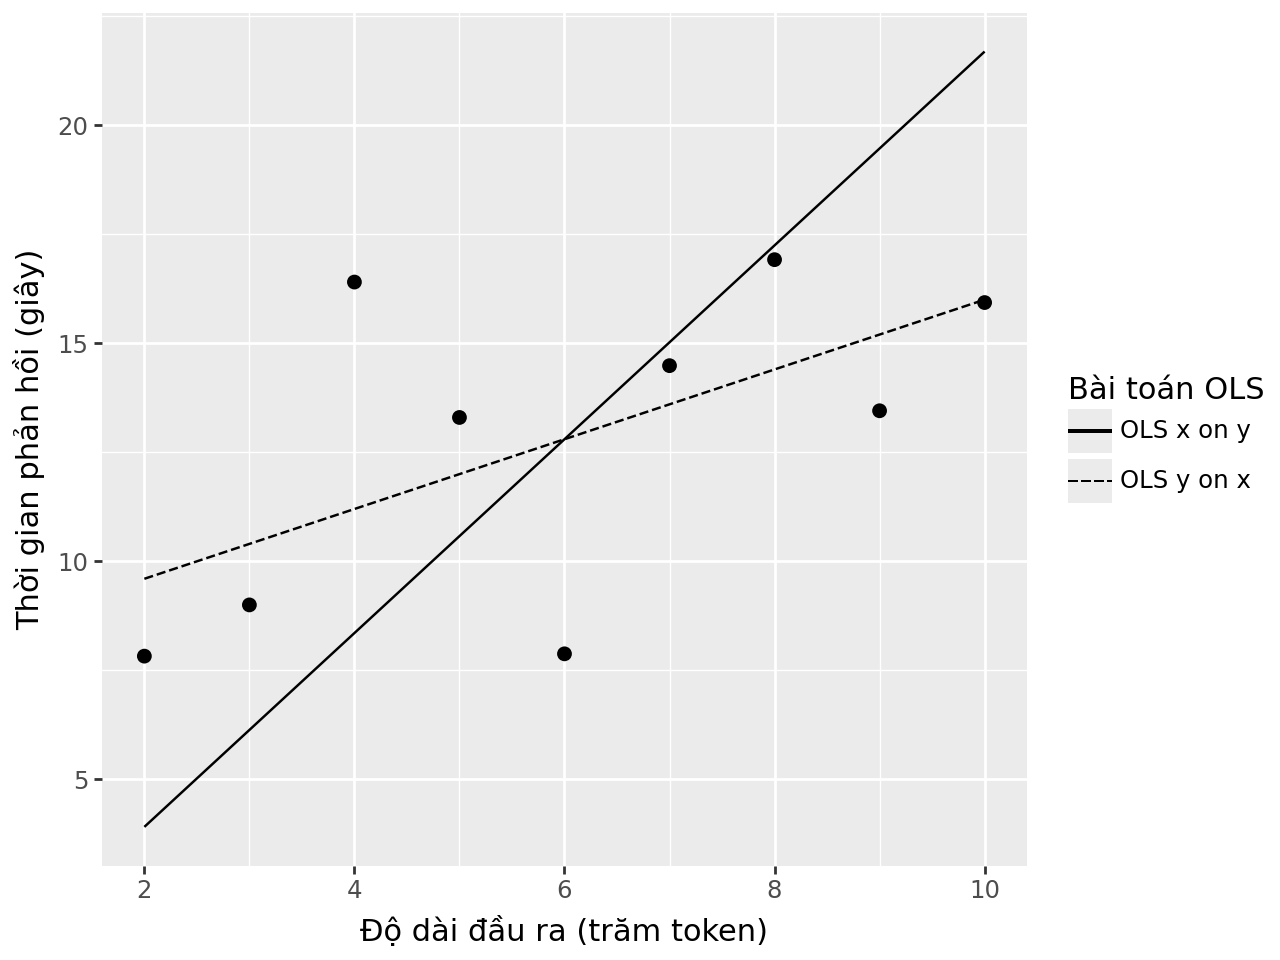

In [13]:
if RUN_LAB02:
    forward = result["simple"]
    reverse = result["reverse"]
    b_yx = float(forward.params["x"])
    b_xy = float(reverse.params["y"])
    print("Slope y theo x:",b_yx)
    print("Slope x theo y:",b_xy)
    print("Tích slope:",b_yx*b_xy,"; r^2 =",result["r"]**2)
    print("Tâm dữ liệu:",data.x.mean(),data.y.mean())
    # Chỉ đảo hệ số khác 0. Vẽ cả hai đường trên trục (x,y).
    grid = np.linspace(data.x.min(),data.x.max(),80)
    lines = pd.DataFrame({"x":grid,"y":forward.params["Intercept"]+b_yx*grid,
                          "fit":"OLS y on x"})
    if abs(b_xy) > 1e-12:
        second = pd.DataFrame({"x":grid,"y":(grid-reverse.params["Intercept"])/b_xy,
                               "fit":"OLS x on y"})
        lines = pd.concat([lines,second],ignore_index=True)
        p = (ggplot(data,aes("x","y"))+geom_point(size=2)
             +geom_line(aes(linetype="fit"),data=lines)
             +labs(x=CONFIG["x_label"],y=CONFIG["y_label"],linetype="Bài toán OLS"))
        display(p)
    else:
        print("Slope ngược bằng/gần 0; không chia cho nó để vẽ y theo x.")


### Bài 9 — Trả lời
1. Có phải cùng đường OLS không? Không , vì bạn suy công thức từ mô hình khớp y = 8 + 0.8x , tức là các đầu vào y_i của phương trình đảo khác với y_i thực tế quan sát được.
2. Điều kiện cần và trường hợp r=0: 
    + Điều kiện cần : r^2 = 1 => r = +- 1 
    + Giả thiết : $s_x,s_y \geq 0$ để $b_{x|y} ,b_{y|x}$ xác định
    + r = 0 : 2 đường hồi quy (x theo y và y theo x) vuông góc.
3. Giải thích hình học:
    + Tổi thiểu theo y : Dùng x quan sát , khớp mô hình để tối thiểu hóa sai số e = $\tilde{y}$ - y.
    + Tổi thiểu theo x : Dùng y quan sát , khớp mô hình để tối thiểu hóa sai số e = $\tilde{x}$ - x
4. Tính từ thống kê tóm tắt và so sánh tại 14 giây: 
    + Từ tóm tắt : $\tilde{x} = 0.45y +10.1. \text{Thay y = 14} \space \to \tilde{x} = 16.4 $
    + Từ ptrinh giải ngược : $\tilde{x} = 7.5$
    $-> Lệch 16,4 - 7,5 = 8.9$
5. Các kiểm tra số học và hình đã tạo: 
$$
b_{\frac{y}{x}} . b_{\frac{y}{x}} = 0,8 x 0.45 = 0.36 = r^2
$$
+ Hồi quy y theo x : 12.8 = 8 + 0.8 * 6 -> Đúng
+ Hồi quy x theo y : 12.8 = 10.1 + 0.45 * 6 -> Đúng

## Bài 10 — Sửa các báo cáo
I: tên bẫy : ngoại suy ngoài vùng quan sát / câu sửa : dự đoán ngoại suy , chỉ dự báo từ mô hình khớp , không có quan sát tại x = 25 để đánh giá độ tin cậy.

II: tên bẫy : hiểu sai hệ số chặn/ câu sửa : số 4 là hệ số chặn của mô hình nhưng chưa chắc có ý nghĩa thực tế vì x = 0 không nằm trong vùng quan sát, không có token đầu vào cũng không phải là 1 đầu vào hợp lệ.

III: tên bẫy : Bỏ qua môi trường(nhóm) / câu sửa : slop gộp là âm nhưng không mô tả quy luật cho từng nhóm cụ thể.

IV: tên bẫy / câu sửa : Bắt nhóm tăng nằm trong vùng quan sát(30-85%) sẽ làm tỉ lệ trả lời thiếu căn cứ giảm 35%.
Thiết kế dữ liệu bổ sung và điểm yếu được xử lý: Đánh giá bổ sung cho ý III. Lấy slop theo nhóm để nhìn rõ mối liên hệ , giải quyết vấn đề gộp làm mất đặc trưng từng môi trường.

## Tự kiểm tra trước khi nộp
Đã ghi tên/mã sinh viên; đã có phần làm tay; đã bật các LAB và lưu output; mỗi hình có nhãn; không diễn giải hệ số thành nhân quả; không có dữ liệu riêng hoặc đường dẫn máy cá nhân không cần thiết trong bài nộp.